<a href="https://colab.research.google.com/github/p2ms/Moderar_com_redes_neurais_FAC/blob/main/baseline_T2_redesNeurais.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

treino=4900  val=1050  teste=1050 (teste NÃO será usado aqui)
n=  100 seed=0 C=  100 F1 treino=1.000 val=0.642 tempo=0.02s
n=  100 seed=1 C=   10 F1 treino=1.000 val=0.668 tempo=0.02s
n=  100 seed=2 C=  0.1 F1 treino=1.000 val=0.659 tempo=0.01s
n=  500 seed=0 C=    1 F1 treino=1.000 val=0.761 tempo=0.07s
n=  500 seed=1 C=  0.1 F1 treino=0.994 val=0.759 tempo=0.05s
n=  500 seed=2 C=   10 F1 treino=1.000 val=0.779 tempo=0.06s
n= 2000 seed=0 C=    1 F1 treino=0.987 val=0.805 tempo=0.49s
n= 2000 seed=1 C=   10 F1 treino=1.000 val=0.822 tempo=0.44s
n= 2000 seed=2 C=   10 F1 treino=1.000 val=0.830 tempo=1.14s
n= 4900 seed=0 C=  100 F1 treino=1.000 val=0.849 tempo=1.39s
n= 4900 seed=1 C=  100 F1 treino=1.000 val=0.849 tempo=1.15s
n= 4900 seed=2 C=  100 F1 treino=1.000 val=0.849 tempo=2.48s

    n  f1_train_mean  f1_train_std  f1_val_mean  f1_val_std  time_mean
 100         1.0000        0.0000       0.6563      0.0132     0.0169
 500         0.9980        0.0035       0.7663      0.0112     0

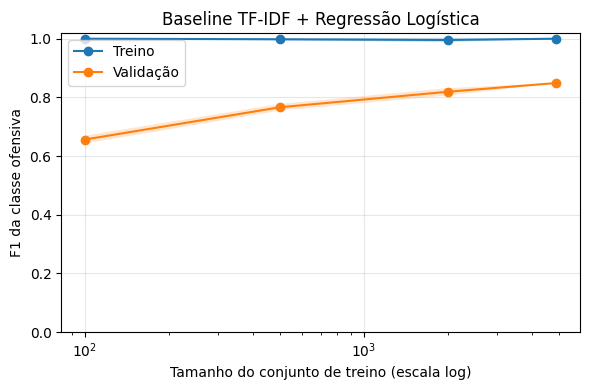

In [2]:
"""
Baseline: TF-IDF (palavras + bigramas) + Regressão Logística
Gera: curva de treino/validação vs. tamanho do treino, tabela com F1 e tempo.

Receita geral (serve para qualquer baseline):
  1. dados congelados (split fixo, índices salvos)
  2. pipeline único (pré-processamento + modelo)
  3. hiperparâmetro escolhido SÓ na validação
  4. medir métrica (treino e validação) + tempo no mesmo laço
  5. várias sementes -> média ± desvio-padrão
  6. figura + parágrafo
"""
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

# ---------------- CONFIGURAÇÃO (ajuste aqui) ----------------
CSV_PATH = "HateBR.csv"      # CSV com os comentários
TEXT_COL = "comentario"            # nome da coluna de texto
LABEL_COL = "label_final"          # nome da coluna do rótulo (1 = ofensivo, 0 = não)
SPLIT_SEED = 42              # semente do split (fixa, nunca muda)
SIZES = [100, 500, 2000, None]   # None = todos os exemplos de treino
SEEDS = [0, 1, 2]            # sementes que variam a amostra do subconjunto
C_GRID = [0.1, 1, 10, 100]   # hiperparâmetro buscado
# -------------------------------------------------------------

# 1) Dados: remover duplicatas e dividir 70/15/15 estratificado
df = pd.read_csv(CSV_PATH).drop_duplicates(subset=TEXT_COL).reset_index(drop=True)
idx = np.arange(len(df))
idx_train, idx_tmp = train_test_split(
    idx, test_size=0.30, stratify=df[LABEL_COL], random_state=SPLIT_SEED
)
idx_val, idx_test = train_test_split(
    idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, LABEL_COL], random_state=SPLIT_SEED
)
# registrar os índices para reprodutibilidade (e para o BERTimbau usar os mesmos)
json.dump(
    {"train": idx_train.tolist(), "val": idx_val.tolist(), "test": idx_test.tolist()},
    open("split_indices.json", "w"),
)
print(f"treino={len(idx_train)}  val={len(idx_val)}  teste={len(idx_test)} (teste NÃO será usado aqui)")

X_val, y_val = df.loc[idx_val, TEXT_COL], df.loc[idx_val, LABEL_COL]


def make_model(C):
    # o vetorizador está DENTRO do pipeline: aprende o vocabulário só do subconjunto de treino
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), lowercase=True),
        LogisticRegression(C=C, max_iter=1000),
    )


def subset(n, seed):
    """Subconjunto estratificado do treino (ou todo o treino se n=None)."""
    if n is None or n >= len(idx_train):
        return idx_train
    sub, _ = train_test_split(
        idx_train, train_size=n, stratify=df.loc[idx_train, LABEL_COL], random_state=seed
    )
    return sub


# 2-4) Laço principal: tamanho x semente x C
rows = []
for n in SIZES:
    for seed in SEEDS:
        sub = subset(n, seed)
        X_tr, y_tr = df.loc[sub, TEXT_COL], df.loc[sub, LABEL_COL]
        best = None
        for C in C_GRID:
            t0 = time.perf_counter()
            model = make_model(C).fit(X_tr, y_tr)
            fit_time = time.perf_counter() - t0
            f1_val = f1_score(y_val, model.predict(X_val), pos_label=1)
            f1_tr = f1_score(y_tr, model.predict(X_tr), pos_label=1)
            if best is None or f1_val > best["f1_val"]:   # escolha SÓ pela validação
                best = dict(C=C, f1_train=f1_tr, f1_val=f1_val, time_s=fit_time)
        rows.append(dict(n=len(sub), seed=seed, **best))
        print(f"n={len(sub):5d} seed={seed} C={best['C']:>5} "
              f"F1 treino={best['f1_train']:.3f} val={best['f1_val']:.3f} "
              f"tempo={best['time_s']:.2f}s")

res = pd.DataFrame(rows)
res.to_csv("baseline_resultados.csv", index=False)

# 5) Agregar: média ± desvio-padrão por tamanho
agg = res.groupby("n").agg(
    f1_train_mean=("f1_train", "mean"), f1_train_std=("f1_train", "std"),
    f1_val_mean=("f1_val", "mean"), f1_val_std=("f1_val", "std"),
    time_mean=("time_s", "mean"),
).reset_index().fillna(0.0)   # std = 0 quando só há amostra única (TF-IDF é determinístico)
print("\n", agg.round(4).to_string(index=False))

# 6) Figura: curva de aprendizado (treino vs validação)
fig, ax = plt.subplots(figsize=(6, 4))
for name, label in [("f1_train", "Treino"), ("f1_val", "Validação")]:
    m, s = agg[f"{name}_mean"], agg[f"{name}_std"]
    ax.plot(agg["n"], m, marker="o", label=label)
    ax.fill_between(agg["n"], m - s, m + s, alpha=0.2)
ax.set_xscale("log")
ax.set_xlabel("Tamanho do conjunto de treino (escala log)")
ax.set_ylabel("F1 da classe ofensiva")
ax.set_title("Baseline TF-IDF + Regressão Logística")
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("baseline_curva.png", dpi=200)
print("\nFigura salva em baseline_curva.png")